# A bare-bones RNN for 7-AGNR spectra

Each *device* is one 7-AGNR with random impurities. The RNN reads its transmission
spectrum T(E) for E = 0 - 1.49 eV (150 steps) and predicts T(E) for **1.50 - 1.60 eV** (11 values).

Data follows the repo rules: round T to 3 decimals, divide by the pristine spectrum, split by configuration seed.

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from pathlib import Path
torch.manual_seed(0); np.random.seed(0)

DATA = "/run/media/shardul/storage/machine_learning/transmission_data/transmission_results/consolidated_data/size_7.npy"
PRIS = Path("../../../7_agnr_pris.npy")
N_CONFIGS = 1000          # configs per concentration (seed = row index)
N_IN, N_OUT = 150, 11     # 0-1.49 eV in, 1.50-1.60 eV out (0.01 eV grid)

## 1. Load and normalise

In [2]:
mm = np.load(DATA, mmap_mode="r")                 # (concentration, seed, energy)
pris = np.round(np.load(PRIS)[:N_IN + N_OUT], 3)
pris = np.where(pris > 0, pris, 1.0)
conc_idx = np.arange(2, 60, 2) // 2 - 1            # c = 2, 4, ..., 58

X, Y, seed = [], [], []
for i in conc_idx:
    T = np.clip(np.round(np.asarray(mm[i, :N_CONFIGS, :N_IN + N_OUT], np.float32), 3) / pris, 0, 1).astype(np.float32)
    X.append(T[:, :N_IN]); Y.append(T[:, N_IN:]); seed.append(np.arange(N_CONFIGS))
X, Y, seed = map(np.concatenate, (X, Y, seed))

# split by seed, never by row
tr, va, te = seed < 640, (seed >= 640) & (seed < 800), seed >= 800
Xtr, Ytr, Xva, Yva, Xte, Yte = [torch.tensor(a) for a in (X[tr], Y[tr], X[va], Y[va], X[te], Y[te])]
print(len(Xtr), len(Xva), len(Xte))

18560 4640 5800


## 2. The model: one GRU, one linear layer

The spectrum is fed one energy at a time. After step 150 the hidden state is mapped to the 11 outputs.

In [3]:
class RNN(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.gru = nn.GRU(1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, N_OUT)
    def forward(self, x, return_states=False):
        states, last = self.gru(x.unsqueeze(-1))     # states: (batch, 150, hidden)
        out = self.head(last[0])
        return (out, states) if return_states else out

model = RNN()
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
loss_fn = nn.MSELoss()

## 3. Train

epoch  1  train 0.0130  val 0.0198
epoch  2  train 0.0067  val 0.0138
epoch  3  train 0.0066  val 0.0137
epoch  4  train 0.0065  val 0.0135
epoch  5  train 0.0065  val 0.0135
epoch  6  train 0.0065  val 0.0135
epoch  7  train 0.0064  val 0.0135
epoch  8  train 0.0065  val 0.0135
epoch  9  train 0.0065  val 0.0135
epoch 10  train 0.0064  val 0.0135
epoch 11  train 0.0065  val 0.0135
epoch 12  train 0.0064  val 0.0135
epoch 13  train 0.0065  val 0.0136
epoch 14  train 0.0065  val 0.0136
epoch 15  train 0.0065  val 0.0135


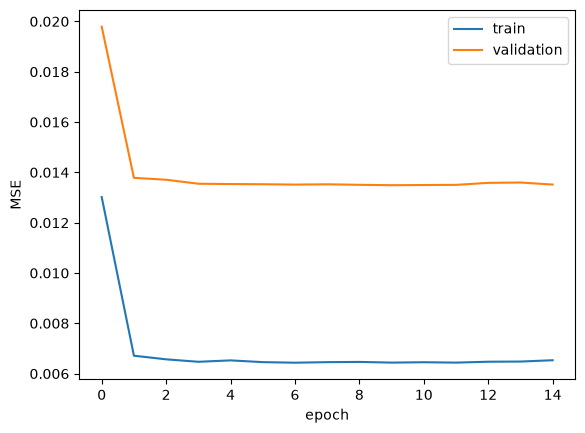

In [4]:
train_loss, val_loss = [], []
for epoch in range(15):
    model.train()
    perm = torch.randperm(len(Xtr))
    for b in perm.split(256):
        opt.zero_grad(); loss_fn(model(Xtr[b]), Ytr[b]).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        train_loss.append(loss_fn(model(Xtr[:5000]), Ytr[:5000]).item())
        val_loss.append(loss_fn(model(Xva), Yva).item())
    print(f"epoch {epoch+1:2d}  train {train_loss[-1]:.4f}  val {val_loss[-1]:.4f}")

plt.plot(train_loss, label="train"); plt.plot(val_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

## 4. How good is it? (test seeds)

Baseline = *persistence*: repeat the last input value (T at 1.49 eV) for all 11 outputs.

RNN         test MSE 0.0136
persistence test MSE 0.0261


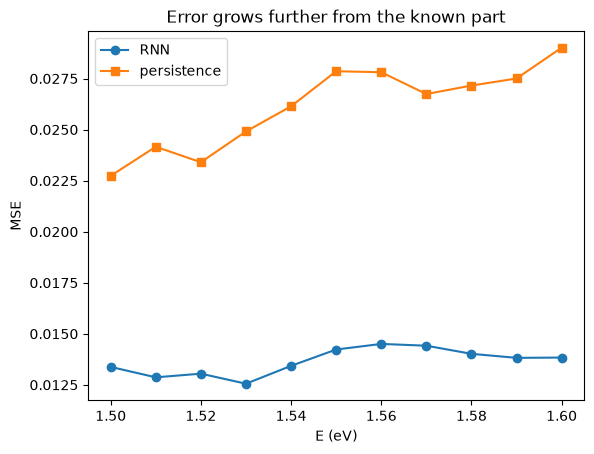

In [5]:
with torch.no_grad():
    pred = model(Xte)
persist = Xte[:, -1:].repeat(1, N_OUT)
print(f"RNN         test MSE {loss_fn(pred, Yte).item():.4f}")
print(f"persistence test MSE {loss_fn(persist, Yte).item():.4f}")

E_out = np.arange(N_IN, N_IN + N_OUT) / 100
plt.plot(E_out, ((pred - Yte)**2).mean(0), "o-", label="RNN")
plt.plot(E_out, ((persist - Yte)**2).mean(0), "s-", label="persistence")
plt.xlabel("E (eV)"); plt.ylabel("MSE"); plt.title("Error grows further from the known part"); plt.legend(); plt.show()

## 5. Predictions on individual devices

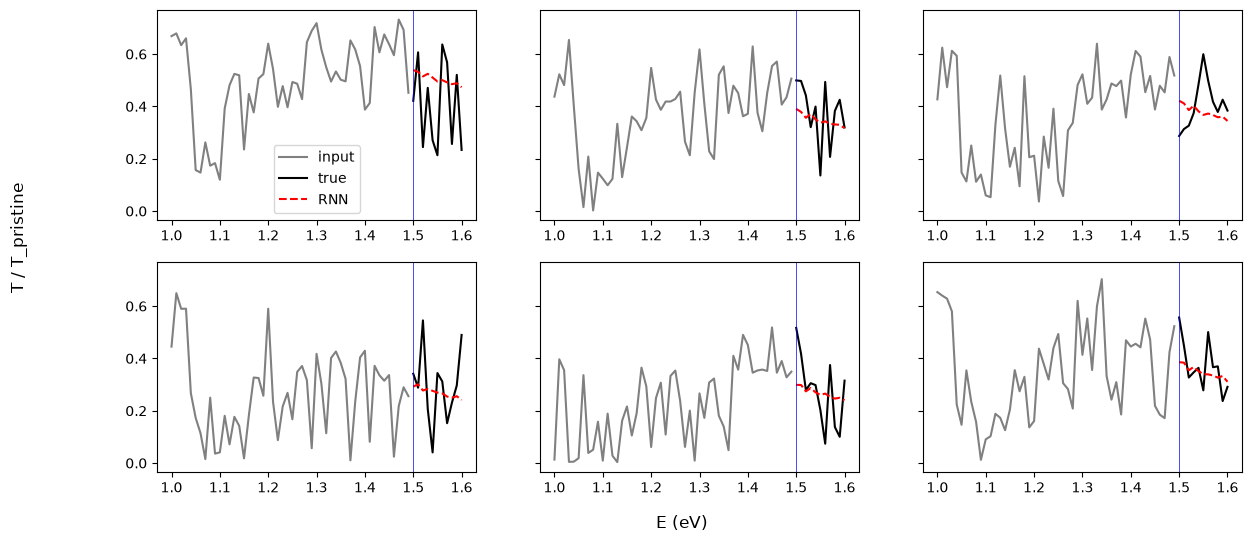

In [6]:
E_in = np.arange(N_IN) / 100
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, k in zip(axes.flat, np.random.choice(len(Xte), 6, replace=False)):
    ax.plot(E_in[-50:], Xte[k, -50:], color="gray", label="input")
    ax.plot(E_out, Yte[k], "k", label="true")
    ax.plot(E_out, pred[k], "r--", label="RNN")
    ax.axvline(1.5, color="b", lw=0.5)
axes[0, 0].legend(); fig.supxlabel("E (eV)"); fig.supylabel("T / T_pristine"); plt.show()

## 6. What the RNN is doing inside

Top: the input spectrum of one device. Bottom: the hidden state (32 units) after each energy step.
Each column is the network's memory at that energy. Watch how units react at sharp features.

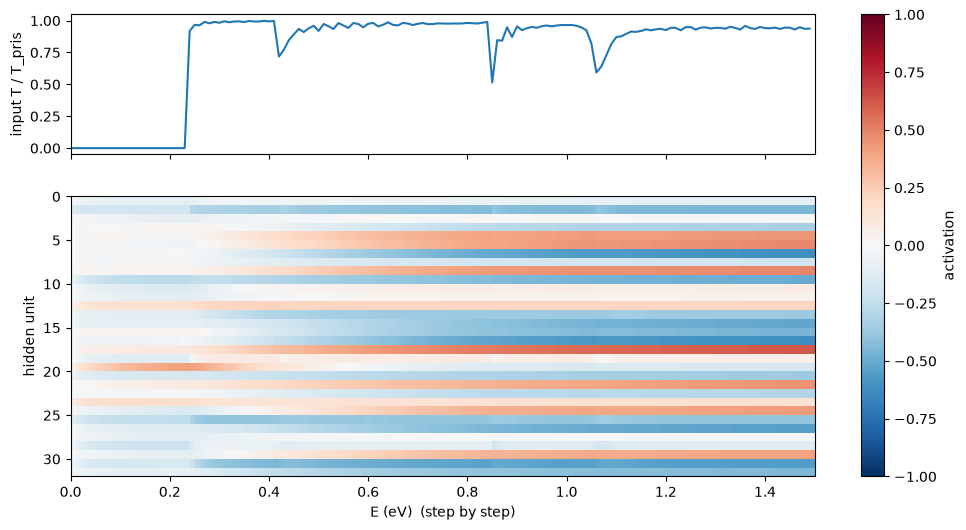

In [7]:
k = 0
with torch.no_grad():
    _, states = model(Xte[k:k+1], return_states=True)
H = states[0].T.numpy()                              # (hidden, 150)

fig, (a, b) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
a.plot(E_in, Xte[k]); a.set_ylabel("input T / T_pris")
im = b.imshow(H, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, extent=[0, 1.5, H.shape[0], 0])
b.set_xlabel("E (eV)  (step by step)"); b.set_ylabel("hidden unit"); plt.colorbar(im, ax=[a, b], label="activation"); plt.show()

## 7. Does it remember? Prediction vs. how much of the spectrum it has seen

Same trained model, but we cut the input short (zero-pad the start) and see how the prediction changes.
Short inputs should hurt: the RNN needs the recent spectrum to extrapolate.

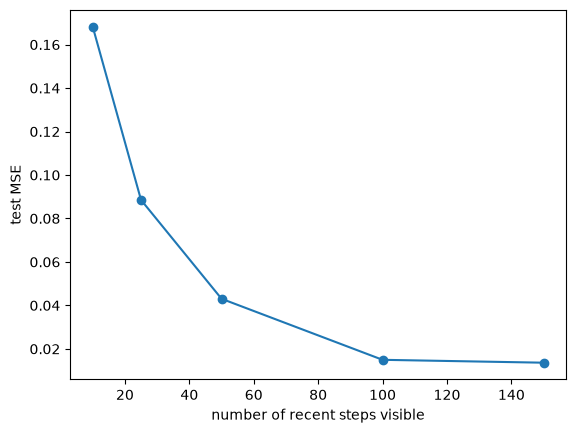

In [8]:
lengths = [10, 25, 50, 100, 150]
errs = []
for L in lengths:
    xs = Xte.clone(); xs[:, :N_IN - L] = 0          # hide everything except the last L steps
    with torch.no_grad():
        errs.append(loss_fn(model(xs), Yte).item())
plt.plot(lengths, errs, "o-"); plt.xlabel("number of recent steps visible"); plt.ylabel("test MSE"); plt.show()